# 1. Exploration des données et tests statistiques

**Objectif** : identifier, parmi les caractéristiques des clients, les variables les plus 
associées à la probabilité de répondre positivement à une campagne de mailing marketing.

La variable cible est `RETOUR` :
- `OUI` : le client a répondu positivement au mailing
- `NON` : le client n'a pas répondu

On combine ici analyse descriptive et tests statistiques (Khi-deux, Student) pour sélectionner 
les variables les plus pertinentes avant la modélisation.

## 1. Importation des bibliothèques

In [1]:
# Bibliothèques de manipulation des données
import pandas as pd
import numpy as np

# Bibliothèques de visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Bibliothèques de tests statistiques
from scipy.stats import chi2_contingency, ttest_ind

# Option d'affichage pour rendre les tableaux plus lisibles
pd.set_option("display.max_columns", None)

## 2. Chargement de la base de données

Le fichier utilisé est `mailing_fin.txt`, séparé par des tabulations (`sep="\t"`).

In [2]:
from pathlib import Path

# Chemins possibles selon l'emplacement du notebook :
# - si le notebook est dans le dossier principal du projet : data/mailing_fin.txt
# - si le notebook est dans le dossier notebooks/ : ../data/mailing_fin.txt
possible_paths = [
    Path("data/mailing_fin.txt"),
    Path("../data/mailing_fin.txt"),
    Path("mailing_fin.txt")
]

# On sélectionne automatiquement le premier chemin qui existe
data_path = None
for path in possible_paths:
    if path.exists():
        data_path = path
        break

if data_path is None:
    raise FileNotFoundError("Le fichier mailing_fin.txt est introuvable. Vérifie qu'il est bien dans le dossier data/.")

df = pd.read_csv(data_path, sep="\t")
df.head()

,RETOUR,AGE,INCOME,SEX,MARRIED,FICO,OWNHOME,LOC,BUY6,BUY12,BUY18,VALUE24,COA6,fin
0,NON,45,52,F,1,748,0,A,0,0,0,209,0,0
1,NON,56,79,NaN,1,732,0,A,0,0,0,109,0,0
2,OUI,49,54,F,0,727,0,A,0,0,1,447,0,0
3,OUI,44,40,NaN,1,708,1,A,0,0,0,151,0,0
4,NON,59,41,F,0,646,1,A,0,0,0,233,0,0


## 3. Contrôle initial de la base

In [3]:
# Nombre de lignes et de colonnes
df.shape

(39779, 14)

In [4]:
# Types des colonnes et valeurs non nulles
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 39779 entries, 0 to 39778
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   RETOUR   39779 non-null  str  
 1   AGE      39779 non-null  int64
 2   INCOME   39779 non-null  int64
 3   SEX      39721 non-null  str  
 4   MARRIED  39779 non-null  int64
 5   FICO     39779 non-null  int64
 6   OWNHOME  39779 non-null  int64
 7   LOC      39779 non-null  str  
 8   BUY6     39779 non-null  int64
 9   BUY12    39779 non-null  int64
 10  BUY18    39779 non-null  int64
 11  VALUE24  39779 non-null  int64
 12  COA6     39779 non-null  int64
 13  fin      39779 non-null  int64
dtypes: int64(11), str(3)
memory usage: 4.2 MB


In [5]:
# Nombre de valeurs manquantes par variable
df.isna().sum()

RETOUR      0
AGE         0
INCOME      0
SEX        58
MARRIED     0
FICO        0
OWNHOME     0
LOC         0
BUY6        0
BUY12       0
BUY18       0
VALUE24     0
COA6        0
fin         0
dtype: int64

## 4. Traitement des valeurs manquantes

La variable `SEX` contient des valeurs manquantes. Comme elles représentent une part 
marginale de la base, on supprime ces observations plutôt que de les imputer.

In [6]:
# Pourcentage de valeurs manquantes dans la variable SEX
df["SEX"].isna().mean() * 100

np.float64(0.14580557580633)

In [7]:
# Suppression des lignes où SEX est manquant
df = df.dropna(subset=["SEX"])
df["SEX"].isna().sum()

np.int64(0)

## 5. Analyse de la variable cible `RETOUR`

La variable cible est déséquilibrée : la majorité des clients n'a pas répondu à la campagne.

In [8]:
df["RETOUR"].value_counts()

RETOUR
NON    34325
OUI     5396
Name: count, dtype: int64

In [9]:
df["RETOUR"].value_counts(normalize=True) * 100

RETOUR
NON    86.415246
OUI    13.584754
Name: proportion, dtype: float64

**Observation** : la variable cible `RETOUR` est déséquilibrée : environ 86,4 % des 
clients n'ont pas répondu à la campagne, contre 13,6 % qui ont répondu positivement. 
Ce déséquilibre devra être pris en compte lors de l'évaluation du modèle 
(l'accuracy seule serait trompeuse).

## 6. Analyse descriptive globale

In [10]:
df.describe()

,AGE,INCOME,MARRIED,FICO,OWNHOME,BUY6,BUY12,BUY18,VALUE24,COA6,fin
count,39721.000000,39721.000000,39721.000000,39721.000000,39721.000000,39721.000000,39721.000000,39721.000000,39721.000000,39721.000000,39721.0
mean,44.301931,47.779512,0.576118,693.690416,0.328819,0.131970,0.216107,0.360238,254.259258,0.029002,0.0
std,10.225257,16.041445,0.494178,28.817799,0.469790,0.351382,0.446451,0.585327,154.468854,0.167815,0.0
min,18.000000,15.000000,0.000000,565.000000,0.000000,0.000000,0.000000,0.000000,60.000000,0.000000,0.0
25%,38.000000,35.000000,0.000000,675.000000,0.000000,0.000000,0.000000,0.000000,149.000000,0.000000,0.0
50%,44.000000,50.000000,1.000000,694.000000,0.000000,0.000000,0.000000,0.000000,215.000000,0.000000,0.0
75%,50.000000,61.000000,1.000000,713.000000,1.000000,0.000000,0.000000,1.000000,312.000000,0.000000,0.0
max,75.000000,128.000000,1.000000,810.000000,1.000000,2.000000,3.000000,4.000000,1317.000000,1.000000,0.0


## 7. Discrétisation de la variable `AGE`

L'âge est transformé en classes afin de faciliter l'interprétation et l'analyse bivariée.

In [11]:
bins = [18, 25, 35, 45, 55, 65, 75]
labels = ["18-25", "26-35", "36-45", "46-55", "56-65", "66-75"]

df["AGE_CAT"] = pd.cut(
    df["AGE"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

df["AGE_CAT"].value_counts().sort_index()

AGE_CAT
18-25     1467
26-35     5932
36-45    15082
46-55    12210
56-65     3782
66-75     1248
Name: count, dtype: int64

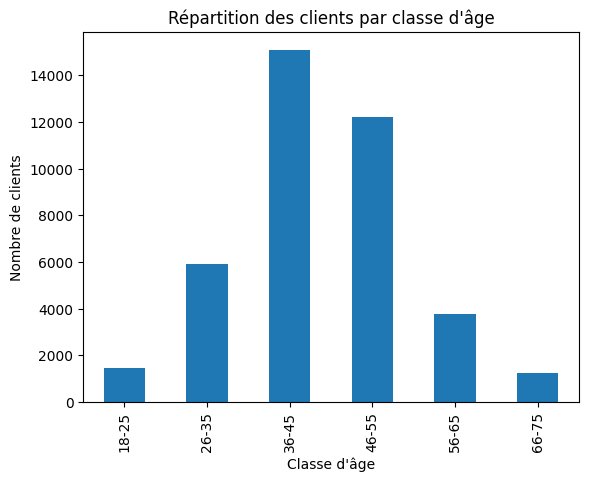

In [12]:
df["AGE_CAT"].value_counts().sort_index().plot(kind="bar")
plt.title("Répartition des clients par classe d'âge")
plt.xlabel("Classe d'âge")
plt.ylabel("Nombre de clients")
plt.show()

## 8. Analyse bivariée : âge et retour

In [13]:
# Tableau croisé en pourcentage par ligne : taux de OUI/NON dans chaque classe d'âge
table_age = pd.crosstab(df["AGE_CAT"], df["RETOUR"], normalize="index") * 100
table_age

RETOUR,NON,OUI
AGE_CAT,,
18-25,69.256987,30.743013
26-35,82.333109,17.666891
36-45,87.077311,12.922689
46-55,87.764128,12.235872
56-65,90.534109,9.465891
66-75,92.307692,7.692308


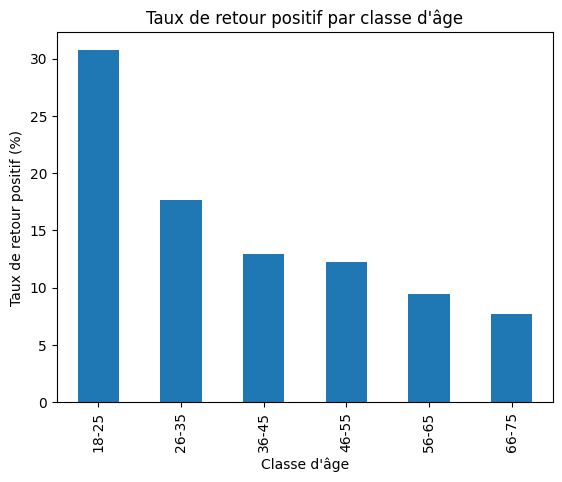

In [14]:
table_age["OUI"].plot(kind="bar")
plt.title("Taux de retour positif par classe d'âge")
plt.xlabel("Classe d'âge")
plt.ylabel("Taux de retour positif (%)")
plt.show()

**Observation** : l'analyse par classes d'âge montre une relation décroissante entre 
l'âge et le taux de retour positif. Les clients de 18 à 25 ans présentent le taux de réponse 
le plus élevé (~30,7 %), contre ~7,7 % pour les 66-75 ans. L'âge semble être une variable 
fortement discriminante.

## 9. Tests du Khi-deux sur les variables qualitatives

Le test du Khi-deux permet de tester l'indépendance entre une variable qualitative et 
la variable cible `RETOUR`.

- **H0** : la variable explicative est indépendante de `RETOUR`
- **H1** : il existe une relation entre la variable explicative et `RETOUR`

Si la p-value est inférieure à 5 %, on rejette H0.

In [15]:
qual_vars = ["AGE_CAT", "SEX", "MARRIED", "OWNHOME", "LOC", "COA6"]

for col in qual_vars:
    table = pd.crosstab(df[col], df["RETOUR"])
    chi2, p_value, dof, expected = chi2_contingency(table)
    print(col, "p-value :", p_value)

AGE_CAT p-value : 1.475919375521899e-120
SEX p-value : 0.0014996077506539383
MARRIED p-value : 2.3777688950964954e-10
OWNHOME p-value : 5.718775149351427e-48
LOC p-value : 1.2660682814175627e-40
COA6 p-value : 0.003003775015993136


In [16]:
# Tableaux croisés pour interpréter le sens de la relation :
# on affiche le taux de retour positif par modalité de chaque variable
for col in qual_vars:
    print("\nVariable :", col)
    table = pd.crosstab(df[col], df["RETOUR"], normalize="index") * 100
    print(table)


Variable : AGE_CAT
RETOUR         NON        OUI
AGE_CAT                      
18-25    69.256987  30.743013
26-35    82.333109  17.666891
36-45    87.077311  12.922689
46-55    87.764128  12.235872
56-65    90.534109   9.465891
66-75    92.307692   7.692308

Variable : SEX
RETOUR        NON        OUI
SEX                         
F       85.828473  14.171527
M       86.927611  13.072389

Variable : MARRIED
RETOUR         NON        OUI
MARRIED                      
0        87.687830  12.312170
1        85.478937  14.521063

Variable : OWNHOME
RETOUR         NON        OUI
OWNHOME                      
0        84.662416  15.337584
1        89.993109  10.006891

Variable : LOC
RETOUR        NON        OUI
LOC                         
A       84.403670  15.596330
B       86.024590  13.975410
C       79.477292  20.522708
D       81.651001  18.348999
E       88.214846  11.785154
F       88.291947  11.708053
G       86.791953  13.208047
H       86.970255  13.029745

Variable : COA6
RETOU

**Observation** : toutes les variables qualitatives testées présentent une p-value 
inférieure au seuil de 5 % — on rejette donc l'hypothèse d'indépendance pour chacune d'elles.

`AGE_CAT`, `OWNHOME` et `LOC` semblent particulièrement discriminantes (p-values très faibles). 
Les jeunes clients, les clients situés en localités C et D, les non-propriétaires présentent 
des taux de retour plus élevés.

## 10. Analyse des variables quantitatives

On compare les moyennes des variables quantitatives selon la variable cible `RETOUR`.

In [17]:
quant_vars = ["INCOME", "FICO", "VALUE24", "BUY6", "BUY12", "BUY18"]

df.groupby("RETOUR")[quant_vars].mean()

,INCOME,FICO,VALUE24,BUY6,BUY12,BUY18
RETOUR,,,,,,
NON,47.768711,694.254304,249.838543,0.129206,0.208594,0.336693
OUI,47.848221,690.103410,282.380282,0.149555,0.263899,0.510007


## 11. Tests de comparaison de moyennes (test de Student)

- **H0** : les moyennes sont égales entre répondants et non-répondants
- **H1** : les moyennes sont différentes

Si la p-value est inférieure à 5 %, la variable est considérée comme significativement 
différente selon `RETOUR`.

In [18]:
for col in quant_vars:
    groupe_non = df[df["RETOUR"] == "NON"][col]
    groupe_oui = df[df["RETOUR"] == "OUI"][col]
    
    # equal_var=False : on ne suppose pas que les variances sont identiques entre les deux groupes
    stat, p_value = ttest_ind(groupe_non, groupe_oui, equal_var=False)
    
    print(col, "p-value :", p_value)

INCOME p-value : 0.7400616620515399
FICO p-value : 1.1678049827932215e-21
VALUE24 p-value : 8.305627828033671e-37
BUY6 p-value : 0.00014664164559129213
BUY12 p-value : 9.135446974135653e-16
BUY18 p-value : 7.393333088674542e-71


**Observation** : `INCOME` n'est pas significative au seuil de 5 %. En revanche, 
`FICO`, `BUY6`, `BUY12`, `BUY18` et `VALUE24` le sont. Les répondants positifs ont un 
comportement d'achat plus actif : `VALUE24`, `BUY6`, `BUY12` et `BUY18` sont plus élevées 
chez les clients ayant répondu positivement.

## Conclusion de l'exploration

L'analyse exploratoire et les tests statistiques permettent de sélectionner les variables 
pertinentes pour la modélisation : `AGE_CAT`, `SEX`, `MARRIED`, `OWNHOME`, `LOC`, `COA6`, 
`FICO`, `BUY6`, `BUY12`, `BUY18`, `VALUE24`. La variable `INCOME` est exclue car non 
significative. La suite du traitement se fait dans `02_modelisation.ipynb`.